Introduction

Présentation des données et traitement

API Open Météo : 

In [1]:
from src.meteo import charger_meteo
from IPython.display import display #Pour afficher des beaux tableaux


#On appelle meteo_pur la data sans aucun traitement telle qu'on  l'a téléchargée de Open Meteo
meteo_pur= charger_meteo("data/raw/openmeteo") 

#Voila un aperçu des données
print(display(meteo_pur.head()), display(meteo_pur.describe()))
#Première remarque, on peut observer que la température moyenne est égale à environ 13 degrés donc froid selon notre convention. 
# C'est l'effet de la nuit sur la température moyenne (certains jours chaud d'été ont une température inférieur à 15°C la nuit mais ne sont pas froids pour autant).
#On prendra ce problème en compte dans notre traitement des données

#On observe bien que nos données couvre du premier janvier 2021 au 31 décembre 2025
print( "Les données couvrent de "+ str(meteo_pur["time"].min()) +" à " +str( meteo_pur["time"].max()))

#On observe bien que les 12 régions de la France métropolitaine (13 - la Corse) sont bien présentes (1 ville par région)
print("On observe bien au total "+str(meteo_pur["ville"].nunique() )+" régions")



,time,temperature_2m,shortwave_radiation,cloud_cover,wind_speed_10m,wind_speed_100m,precipitation,ville
0,2021-01-01 00:00:00+00:00,4.4,0.0,95,3.1,5.5,0.0,bordeaux
1,2021-01-01 01:00:00+00:00,3.3,0.0,96,3.4,3.5,0.0,bordeaux
2,2021-01-01 02:00:00+00:00,2.1,0.0,92,5.4,5.8,0.0,bordeaux
3,2021-01-01 03:00:00+00:00,1.9,0.0,92,5.9,12.0,0.0,bordeaux
4,2021-01-01 04:00:00+00:00,1.8,0.0,82,6.6,16.6,0.0,bordeaux


,temperature_2m,shortwave_radiation,cloud_cover,wind_speed_10m,wind_speed_100m,precipitation
count,525888.000000,525888.000000,525888.000000,525888.000000,525888.000000,525888.000000
mean,12.986467,151.895489,61.493029,12.207613,20.616850,0.099247
std,7.283659,227.364982,41.271378,6.945876,10.762091,0.457567
min,-11.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,7.900000,0.000000,15.000000,7.100000,12.800000,0.000000
50%,12.700000,7.000000,83.000000,10.900000,19.700000,0.000000
75%,18.000000,249.000000,100.000000,16.000000,26.800000,0.000000
max,41.700000,958.000000,100.000000,69.900000,102.400000,24.400000


None None
Les données couvrent de 2021-01-01 00:00:00+00:00 à 2025-12-31 23:00:00+00:00
On observe bien au total 12 régions


balhbalh

In [2]:
from src.meteo import preparer_meteo
#Les données sont globalement déjà propres
print("pour chaque variable, on vérifie bien qu'on a toutes les observations", meteo_pur.isna().sum(), "puis combien de doublon il y a",meteo_pur.duplicated(["ville", "time"]).sum())
#Les noms de colonnes sont également assez explicites donc on a pas vraiment trouvé d'intérêt à les renommer.

meteo = preparer_meteo(meteo_pur) 
meteo.head()

pour chaque variable, on vérifie bien qu'on a toutes les observations time                   0
temperature_2m         0
shortwave_radiation    0
cloud_cover            0
wind_speed_10m         0
wind_speed_100m        0
precipitation          0
ville                  0
dtype: int64 puis combien de doublon il y a 0


,time,temperature_2m,shortwave_radiation,cloud_cover,wind_speed_10m,wind_speed_100m,precipitation,ville,jour,sous_15,sup_27,deg_sous_15,deg_sup_27,tmax_jour,tmoy_jour,jour_chaud,jour_froid,vent100_moy_jour,vent100_max_jour
0,2021-01-01 01:00:00+01:00,4.4,0.0,95,3.1,5.5,0.0,bordeaux,2021-01-01,True,False,10.6,0.0,6.1,3.752174,False,True,18.308696,28.0
1,2021-01-01 02:00:00+01:00,3.3,0.0,96,3.4,3.5,0.0,bordeaux,2021-01-01,True,False,11.7,0.0,6.1,3.752174,False,True,18.308696,28.0
2,2021-01-01 03:00:00+01:00,2.1,0.0,92,5.4,5.8,0.0,bordeaux,2021-01-01,True,False,12.9,0.0,6.1,3.752174,False,True,18.308696,28.0
3,2021-01-01 04:00:00+01:00,1.9,0.0,92,5.9,12.0,0.0,bordeaux,2021-01-01,True,False,13.1,0.0,6.1,3.752174,False,True,18.308696,28.0
4,2021-01-01 05:00:00+01:00,1.8,0.0,82,6.6,16.6,0.0,bordeaux,2021-01-01,True,False,13.2,0.0,6.1,3.752174,False,True,18.308696,28.0


blahblah

Rapide exploration des données d'Open Meteo

Nous allons effectuer quelques graphiques utiles pour explorer nos données et plus tard pour considérer nos hypothèses.

Tout d'abords pour vérifier la corrélation entre production d'énérgie hydraulique et précipatation, il sera utile d'avoir un graphe des précipitations. On regroupe les données par mois et on affiche le graphique pour Bordeaux.

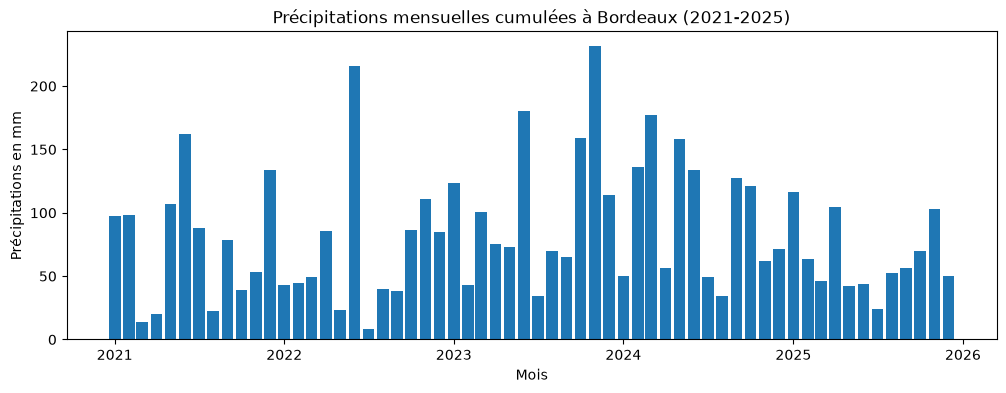

In [ ]:
import matplotlib.pyplot as plt
from src.meteo import tracer_cumul_mensuel_precipitation
ville = "bordeaux"
tracer_cumul_mensuel_precipitation(meteo, ville)


blahblah

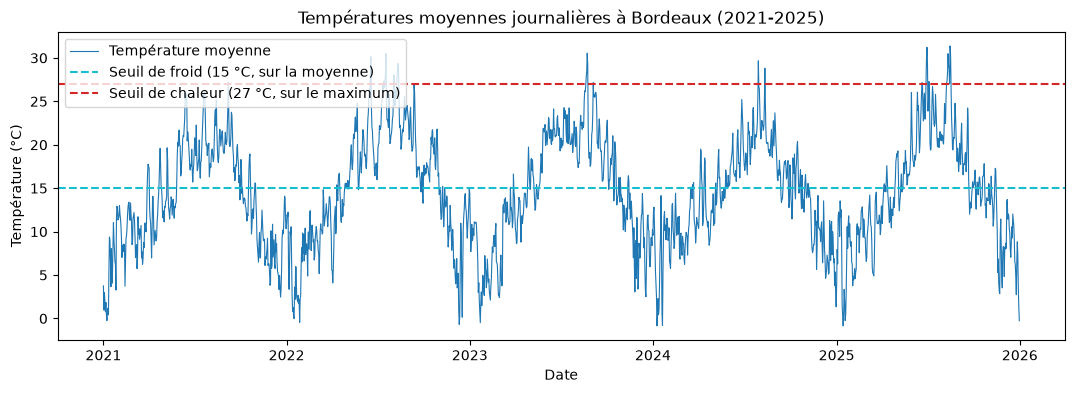

In [4]:
import src.meteo
from src.meteo import tracer_temperature_moyenne_jour, SEUIL_FROID, SEUIL_CHAUD

ville = "bordeaux"
tracer_temperature_moyenne_jour(meteo,ville)

#On observe que très peu de jours sont au dessus du seuil de chaleur (27 degré). C'est "l'effet nuit qu'on a déjà mentionné.
#On génère donc en ne prenant que les données entre 8h et 20h (C'est un choix assez arbitraire car le jour et la nuit commence différement selon les saisons mais c'est le choix que l'on a fait ici.)

Blahblah

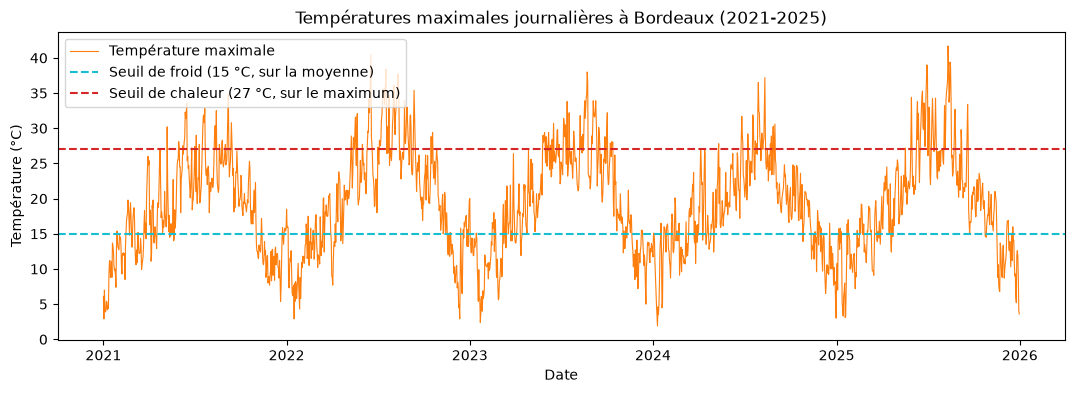

In [5]:
from src.meteo import tracer_temperature_max_jour, SEUIL_FROID, SEUIL_CHAUD

ville = "bordeaux"
tracer_temperature_max_jour(meteo,ville)


Blah bah

In [6]:
# Un seul enregistrement par ville et par jour
jours = meteo.drop_duplicates(["ville", "jour"])

# Nombre de jours froids par ville (2021-2025)
jours_froids = jours.groupby("ville")["jour_froid"].sum().sort_values(ascending=False)
print("Jours froids par ville :")
print(jours_froids)

# Nombre de jours chauds par ville (2021-2025)
jours_chauds = jours.groupby("ville")["jour_chaud"].sum().sort_values(ascending=False)
print("\nJours chauds par ville :")
print(jours_chauds)

Jours froids par ville :
ville
rouen         1233
lille         1220
dijon         1192
rennes        1168
paris         1156
orleans       1152
strasbourg    1145
nantes        1090
lyon          1084
bordeaux       994
toulouse       986
marseille      857
Name: jour_froid, dtype: int64

Jours chauds par ville :
ville
toulouse      349
marseille     310
lyon          293
bordeaux      265
strasbourg    198
dijon         171
paris         161
orleans       158
nantes        147
rennes        122
rouen          85
lille          82
Name: jour_chaud, dtype: int64


Blah blah

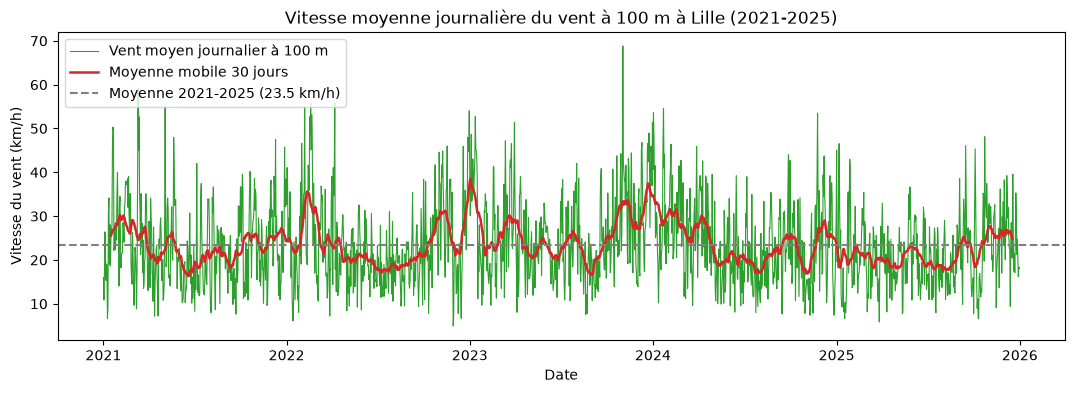

In [7]:
#Et enfin même travail pour la vitesse du vent à 100m (les éoliennes font plus de 100m)
import matplotlib.pyplot as plt
from src.meteo import tracer_vent_moyen_jour

ville = "lille"
tracer_vent_moyen_jour(meteo, ville)

Blah blah

API : ECO2Mix

In [8]:
import pandas as pd

#On appelle elec_pur les données éCO2mix telles qu'on les a téléchargées depuis l'API ODRÉ
from src.electricite import charger_eco2mix

elec_pur = charger_eco2mix()

#Aperçu des données
display(elec_pur.head())

#Vérification de la période couverte et du nombre de régions
print("Les données couvrent de " + str(elec_pur["date_heure"].min()) + " à " + str(elec_pur["date_heure"].max()))
print("On observe au total " + str(elec_pur["code_insee_region"].nunique()) + " régions")


,code_insee_region,libelle_region,date_heure,consommation,nucleaire,eolien,solaire,hydraulique
0,44,Grand Est,2025-12-31T23:30:00+00:00,5870.0,8963.0,45,0.0,524.0
1,11,Île-de-France,2025-12-31T23:30:00+00:00,10410.0,0.0,0,0.0,5.0
2,52,Pays de la Loire,2025-12-31T23:30:00+00:00,4569.0,0.0,934,0.0,3.0
3,24,Centre-Val de Loire,2025-12-31T23:30:00+00:00,3139.0,10323.0,148,0.0,3.0
4,76,Occitanie,2025-12-31T23:30:00+00:00,6387.0,1247.0,55,0.0,1377.0


Les données couvrent de 2021-01-01T00:00:00+00:00 à 2025-12-31T23:30:00+00:00
On observe au total 12 régions


In [9]:
from src.electricite import preparer_eco2mix

#On passe de la demi-heure à l'heure (moyenne des deux demi-heures, car ce sont des puissances en MW)
#et on associe à chaque région son chef-lieu, pour pouvoir fusionner avec la météo
elec_horaire = preparer_eco2mix(elec_pur)

display(elec_horaire.head())
print("Nombre de lignes : " + str(len(elec_horaire)))


,code_insee_region,time,consommation,nucleaire,eolien,solaire,hydraulique,ville
0,11,2021-01-01 00:00:00+00:00,9495.0,0.0,1.0,0.0,3.0,paris
1,11,2021-01-01 01:00:00+00:00,9061.0,0.0,1.5,0.0,3.0,paris
2,11,2021-01-01 02:00:00+00:00,8690.0,0.0,0.0,0.0,3.0,paris
3,11,2021-01-01 03:00:00+00:00,8429.0,0.0,0.0,0.0,3.0,paris
4,11,2021-01-01 04:00:00+00:00,8446.5,0.0,0.5,0.0,3.0,paris


Nombre de lignes : 525828


Après passage à l'heure, on obtient 525 828 lignes au lieu des 525 888 attendues (12 villes × 1 826 jours × 24 heures). Il manque une heure par an et par région : celle du passage à l'heure d'hiver en octobre (00h-01h UTC), absente des données RTE. Ces 60 heures, soit 0,01 % des données, seront écartées lors de la jointure avec la météo.


Jointure entre les deux bases de données

In [10]:
#On fusionne l'électricité (elec_horaire) et la météo préparée (meteo) sur la ville et l'heure.
#Les deux colonnes time ont des fuseaux différents (UTC et Paris) mais pandas les compare comme des instants.
donnees = pd.merge(elec_horaire, meteo, on=["ville", "time"], how="inner")
#Après la fusion, time est en UTC (fuseau du tableau de gauche) : on le remet en heure française pour les analyses par heure
donnees["time"] = donnees["time"].dt.tz_convert("Europe/Paris")

display(donnees.head())
print("Nombre de lignes après jointure : " + str(len(donnees)))
print("Valeurs manquantes : " + str(donnees.isna().sum().sum()))


,code_insee_region,time,consommation,nucleaire,eolien,solaire,hydraulique,ville,temperature_2m,shortwave_radiation,...,sous_15,sup_27,deg_sous_15,deg_sup_27,tmax_jour,tmoy_jour,jour_chaud,jour_froid,vent100_moy_jour,vent100_max_jour
0,11,2021-01-01 01:00:00+01:00,9495.0,0.0,1.0,0.0,3.0,paris,-0.6,0.0,...,True,False,15.6,0.0,3.6,0.291304,False,True,8.995652,12.7
1,11,2021-01-01 02:00:00+01:00,9061.0,0.0,1.5,0.0,3.0,paris,-1.6,0.0,...,True,False,16.6,0.0,3.6,0.291304,False,True,8.995652,12.7
2,11,2021-01-01 03:00:00+01:00,8690.0,0.0,0.0,0.0,3.0,paris,-2.0,0.0,...,True,False,17.0,0.0,3.6,0.291304,False,True,8.995652,12.7
3,11,2021-01-01 04:00:00+01:00,8429.0,0.0,0.0,0.0,3.0,paris,-1.8,0.0,...,True,False,16.8,0.0,3.6,0.291304,False,True,8.995652,12.7
4,11,2021-01-01 05:00:00+01:00,8446.5,0.0,0.5,0.0,3.0,paris,-1.9,0.0,...,True,False,16.9,0.0,3.6,0.291304,False,True,8.995652,12.7


Nombre de lignes après jointure : 525816
Valeurs manquantes : 0


La jointure donne 525 816 lignes. On perd les 60 heures absentes d'éCO2mix au passage à l'heure d'hiver, ainsi que la dernière heure du 31/12/2025, qui tombe en 2026 en heure française. Il n'y a aucune valeur manquante : les deux bases sont prêtes pour l'analyse.


Analyses de nos hypothèses

In [11]:
#Consommation

In [12]:
#Hypothèse consommation : on passe à l'échelle du jour pour neutraliser l'effet jour/nuit.
#Pour chaque ville et chaque jour, on calcule la consommation moyenne et la température moyenne.
conso_jour = (donnees
              .groupby(["ville", "jour"])[["consommation", "temperature_2m"]]
              .mean()
              .reset_index())

print("Nombre de jours × villes : " + str(len(conso_jour)))


Nombre de jours × villes : 21912


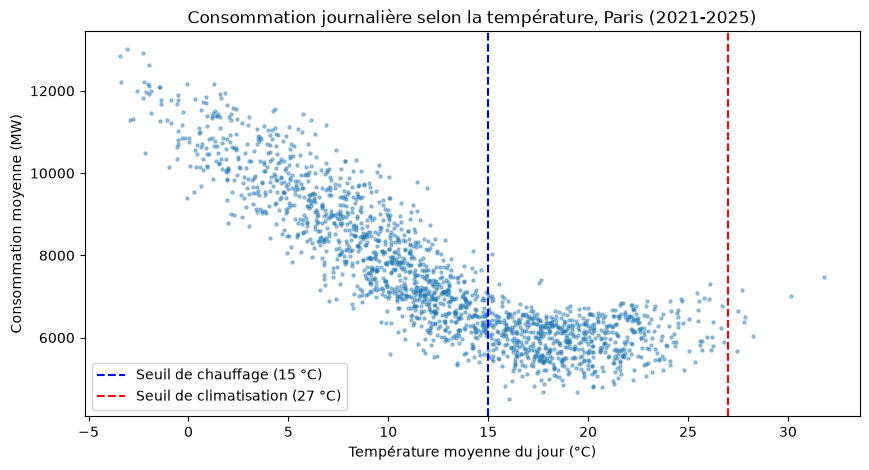

In [13]:
import matplotlib.pyplot as plt
from src.meteo import SEUIL_FROID, SEUIL_CHAUD

ville = "paris"
d = conso_jour[conso_jour["ville"] == ville]

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(d["temperature_2m"], d["consommation"], s=5, alpha=0.4)
ax.axvline(SEUIL_FROID, color="blue", linestyle="--", label="Seuil de chauffage (" + str(SEUIL_FROID) + " °C)")
ax.axvline(SEUIL_CHAUD, color="red", linestyle="--", label="Seuil de climatisation (" + str(SEUIL_CHAUD) + " °C)")
ax.set_title("Consommation journalière selon la température, " + ville.capitalize() + " (2021-2025)")
ax.set_xlabel("Température moyenne du jour (°C)")
ax.set_ylabel("Consommation moyenne (MW)")
ax.legend()
plt.show()



In [14]:
def correlation(df):
    """Corrélation entre la température et la consommation d'un sous-tableau."""
    return df["temperature_2m"].corr(df["consommation"])

#Corrélation calculée uniquement sur les jours froids (sous le seuil de chauffage), région par région
jours_froids = conso_jour[conso_jour["temperature_2m"] < SEUIL_FROID]
correl_froid = jours_froids.groupby("ville").apply(correlation).sort_values()
display(correl_froid)

#Nombre de jours au-dessus du seuil de climatisation, par ville
display((conso_jour["temperature_2m"] > SEUIL_CHAUD).groupby(conso_jour["ville"]).sum())


ville
paris        -0.882959
rouen        -0.877842
orleans      -0.874250
bordeaux     -0.868869
toulouse     -0.860610
rennes       -0.858371
lyon         -0.846217
nantes       -0.837996
lille        -0.826669
dijon        -0.825883
marseille    -0.800558
strasbourg   -0.792968
dtype: float64

ville
bordeaux      34
dijon         10
lille          2
lyon          47
marseille     42
nantes        15
orleans        8
paris          8
rennes         8
rouen          2
strasbourg    10
toulouse      70
Name: temperature_2m, dtype: int64

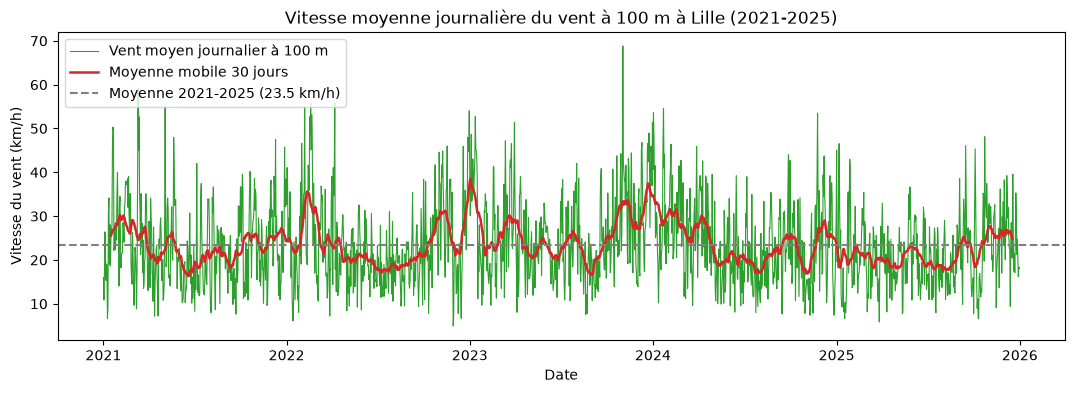

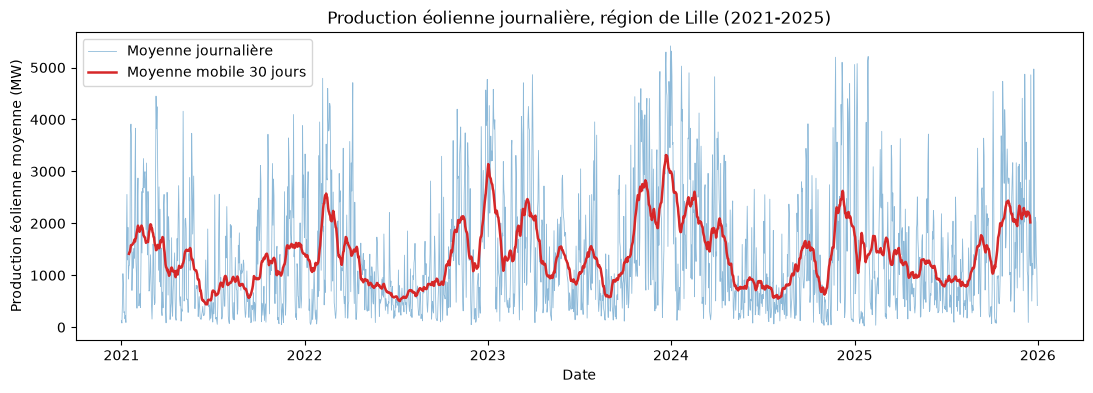

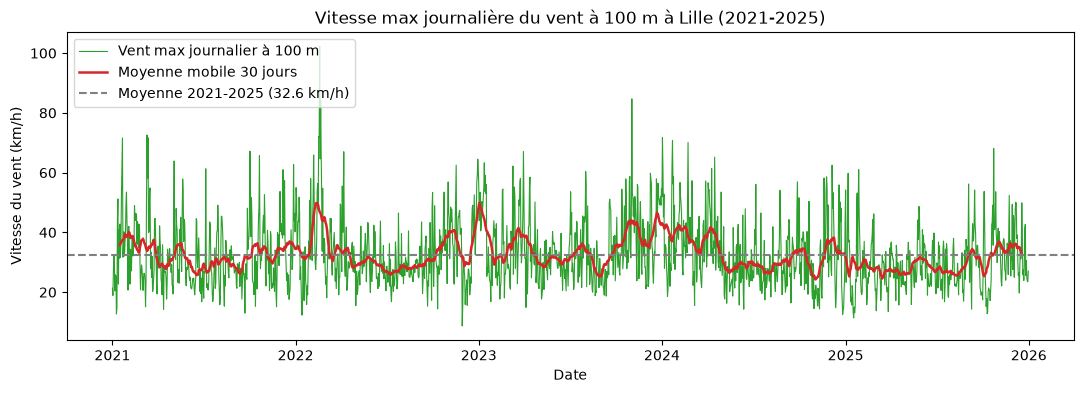

In [15]:
#Production 1 : La production éolienne augmente avec la vitesse du vent.

from src.stats_graph import tracer_graphique_eolien
from src.meteo import tracer_vent_moyen_jour
from src.meteo import tracer_vent_max_jour

ville = "lille"
tracer_vent_moyen_jour(meteo, ville)
tracer_graphique_eolien(donnees, ville)
tracer_vent_max_jour(meteo, ville)
#En regargant les moyennes mobiles, on observe clairement que les graphs sont à peu de choses près identiques : 
# ils ont des pics au même moment (dans le cas de Strasbourg par exemple on peut observer les pics de novembre et janvier 2024)
#Cela confirme (sans aucunes surprises) notre hypothèse de causalité entre la production éolien et la vitesse du vent.
#On va étudier l'effet plus en détail


Blahblah

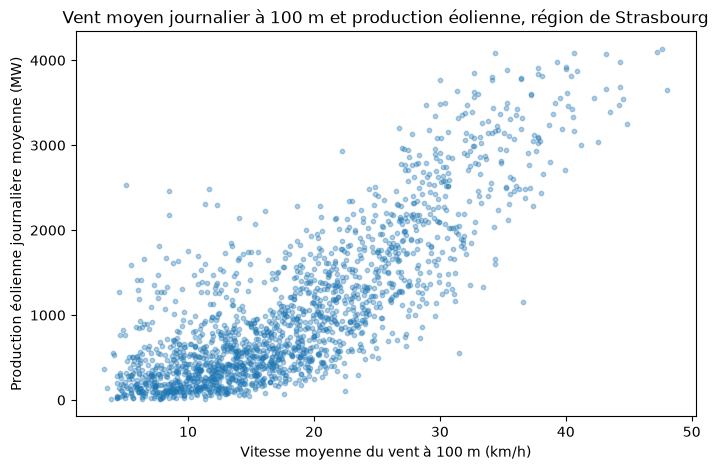

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
from src.stats_graph import tracer_scatter_vent_eolien


tracer_scatter_vent_eolien(donnees, "strasbourg")
#On observe toujours plus ou moins une relation avec une sor

Blah blah

In [17]:
#Production 2 : La production solaire suit l'ensoleillement : nulle la nuit, maximale vers midi et en été

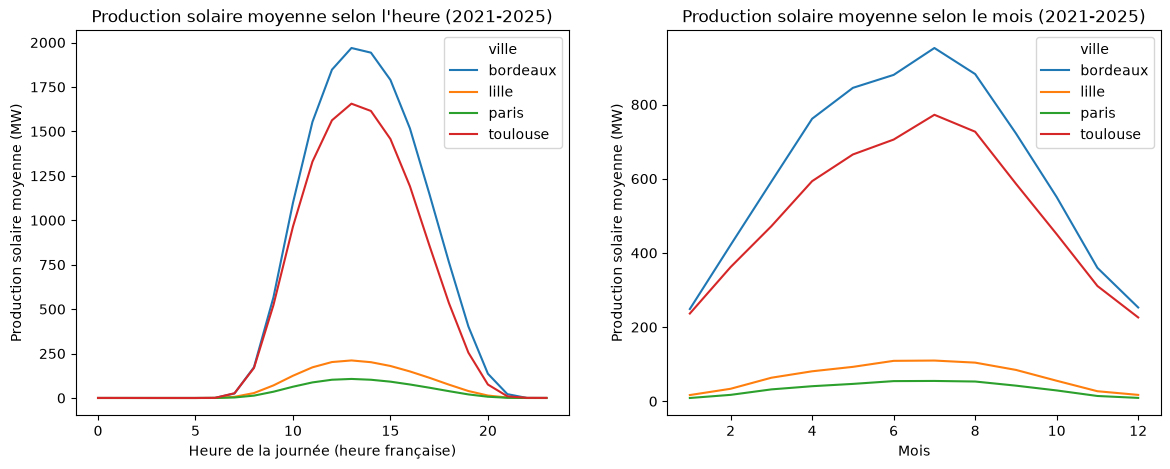

In [18]:
import matplotlib.pyplot as plt

#Hypothèse solaire : on extrait l'heure de la journée et le mois (time est déjà en heure française)
donnees["heure"] = donnees["time"].dt.hour
donnees["mois"] = donnees["time"].dt.month

#On compare deux régions très solaires du Sud et deux régions du Nord
villes = ["toulouse", "bordeaux", "paris", "lille"]
d = donnees[donnees["ville"].isin(villes)]

#Production solaire moyenne pour chaque heure (puis chaque mois), une colonne par ville
profil_heure = d.groupby(["heure", "ville"])["solaire"].mean().unstack()
profil_mois = d.groupby(["mois", "ville"])["solaire"].mean().unstack()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

profil_heure.plot(ax=axes[0])
axes[0].set_title("Production solaire moyenne selon l'heure (2021-2025)")
axes[0].set_xlabel("Heure de la journée (heure française)")
axes[0].set_ylabel("Production solaire moyenne (MW)")

profil_mois.plot(ax=axes[1])
axes[1].set_title("Production solaire moyenne selon le mois (2021-2025)")
axes[1].set_xlabel("Mois")
axes[1].set_ylabel("Production solaire moyenne (MW)")

plt.show()


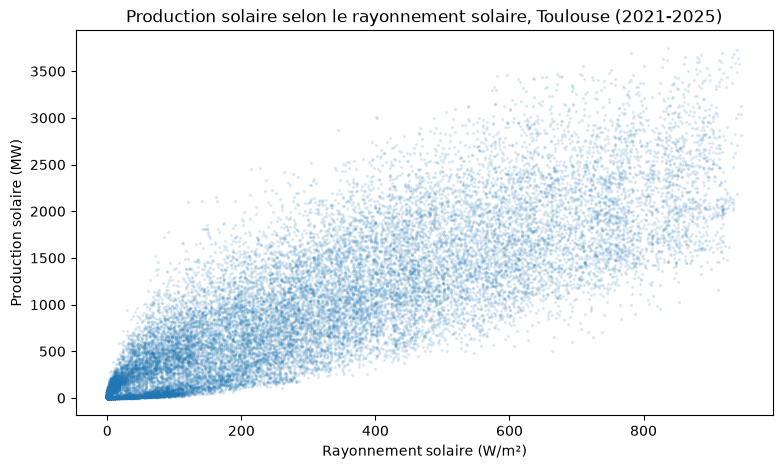

In [19]:
ville = "toulouse"
t = donnees[donnees["ville"] == ville]

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(t["shortwave_radiation"], t["solaire"], s=2, alpha=0.1)
ax.set_title("Production solaire selon le rayonnement solaire, " + ville.capitalize() + " (2021-2025)")
ax.set_xlabel("Rayonnement solaire (W/m²)")
ax.set_ylabel("Production solaire (MW)")
plt.show()


In [20]:
def correlation_solaire(df):
    """Corrélation entre le rayonnement solaire et la production solaire d'un sous-tableau."""
    return df["shortwave_radiation"].corr(df["solaire"])

correl_solaire = donnees.groupby("ville").apply(correlation_solaire).sort_values()
display(correl_solaire)


ville
dijon         0.830548
rennes        0.831783
strasbourg    0.838301
lille         0.842761
paris         0.849774
orleans       0.857390
nantes        0.859363
rouen         0.874335
lyon          0.877835
toulouse      0.908257
bordeaux      0.914521
marseille     0.921366
dtype: float64

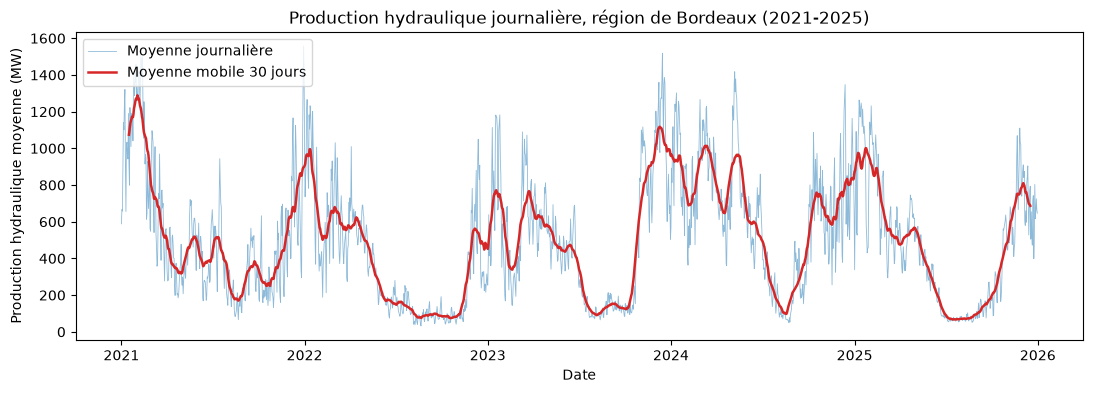

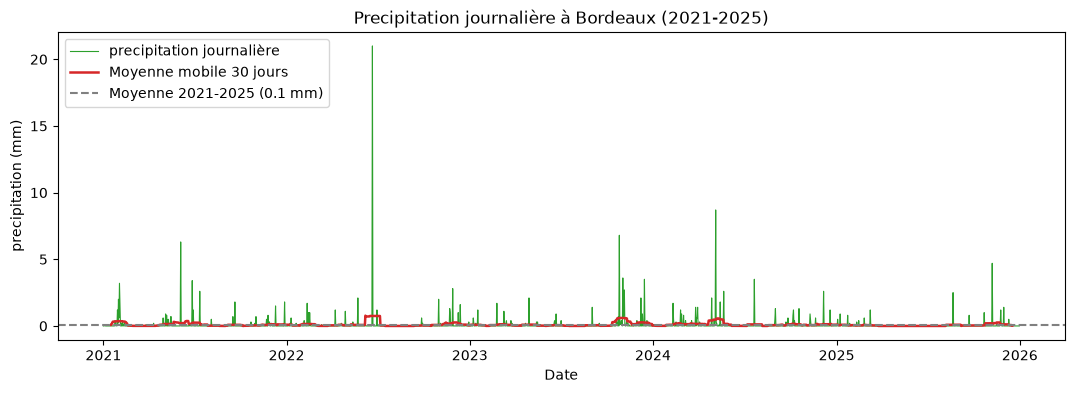

In [21]:
#Production 3 :La production hydraulique dépend des précipitations, avec un décalage dans le temps.
import importlib
import src.stats_graph
importlib.reload(src.stats_graph)
from src.stats_graph import tracer_graphique_hydrau, tracer_hydrau_mois
from src.meteo import tracer_precipitation_jour, tracer_cumul_mensuel_precipitation

ville="bordeaux"
#Si on essaie la même méthode que dans production 1, ce n'est pas très lisible...
tracer_graphique_hydrau(donnees, ville, col_prod="hydraulique", groupe="ville")
tracer_precipitation_jour(meteo, ville)


blah blah

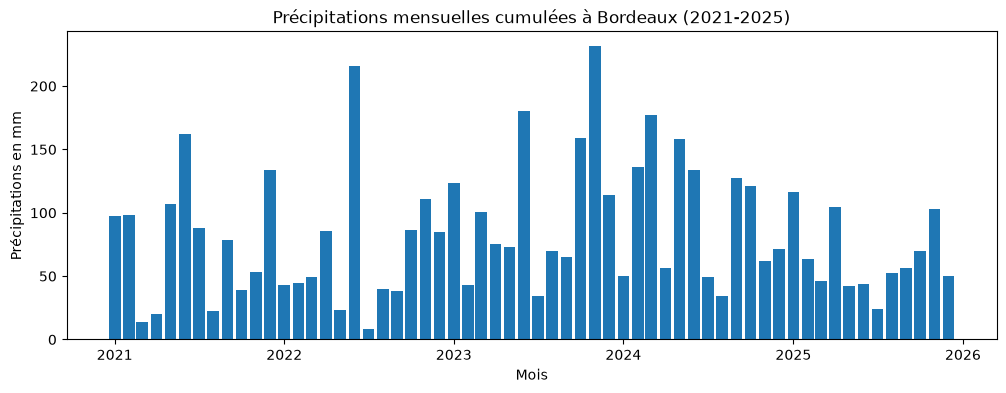

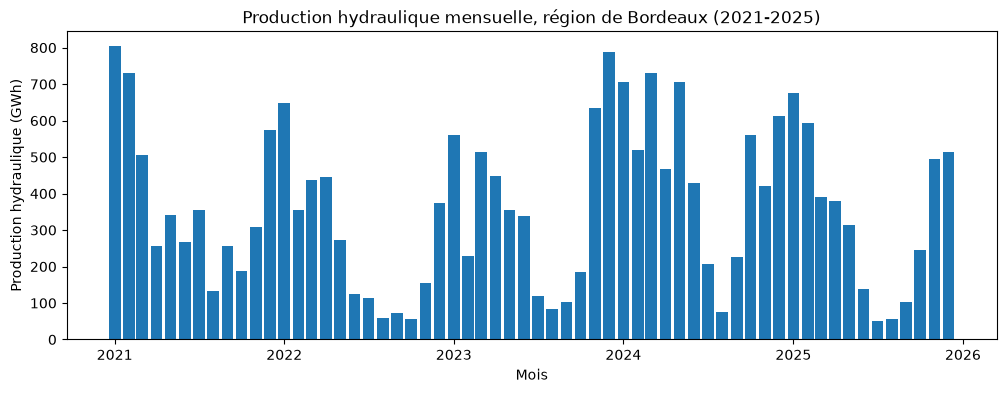

In [22]:
import importlib
import src.stats_graph
importlib.reload(src.stats_graph)
from src.stats_graph import tracer_graphique_hydrau, tracer_hydrau_mois
from src.meteo import tracer_precipitation_jour, tracer_cumul_mensuel_precipitation

ville="bordeaux"
#Donc on va plutot réutiliser notre fonction de cumul mensuel.
tracer_cumul_mensuel_precipitation(meteo,ville)
tracer_hydrau_mois(donnees, ville, col_prod="hydraulique")

Blah blah

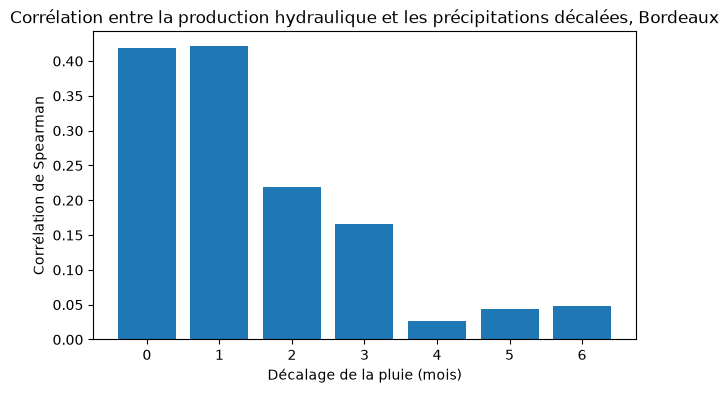

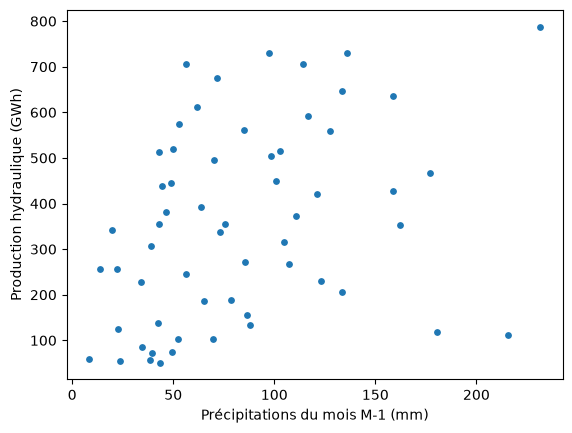

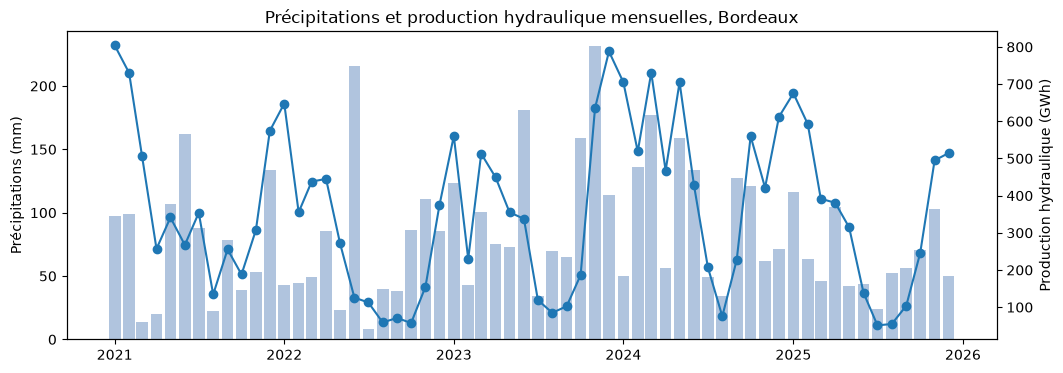

In [23]:
import pandas as pd
import importlib
import src.stats_graph
importlib.reload(src.stats_graph) 
from src.meteo import cumul_mensuel_precipitation
from src.stats_graph import production_mensuelle, corr, tracer_graph_hydrau_pluie, tracer_scatter_pluie_prec


ville = "bordeaux"   # Auvergne-Rhône-Alpes : région hydraulique majeure

pluie =cumul_mensuel_precipitation(meteo,ville)
pluie.index = pluie.index.tz_localize(None)          # même format d'index que la production
prod = production_mensuelle(donnees, ville, "hydraulique")

corr(pluie,prod,ville)

tracer_scatter_pluie_prec(pluie,prod,ville)
tracer_graph_hydrau_pluie(pluie,prod,ville)

Blah blah

#4 Production nucléaire

In [24]:
#Hypothèse nucléaire : on ne garde que les régions qui ont des centrales (production moyenne > 0)
nuc_moyen = donnees.groupby("ville")["nucleaire"].mean()
villes_nucleaires = nuc_moyen[nuc_moyen > 0].index.tolist()
print("Régions avec centrales : " + str(villes_nucleaires))

#Échelle du jour : production nucléaire moyenne et température MAXIMALE du jour
#(c'est la chaleur de l'après-midi qui réchauffe les fleuves)
nuc_jour = (donnees[donnees["ville"].isin(villes_nucleaires)]
            .groupby(["ville", "jour"])
            .agg(nucleaire=("nucleaire", "mean"), tmax=("temperature_2m", "max"))
            .reset_index())
nuc_jour["jour"] = pd.to_datetime(nuc_jour["jour"])
nuc_jour["mois"] = nuc_jour["jour"].dt.month
nuc_jour["annee"] = nuc_jour["jour"].dt.year

#On compare uniquement les jours d'été entre eux : les centrales sont souvent en maintenance l'été,
#comparer l'été à l'hiver mélangerait l'effet de la chaleur et celui de la maintenance
ete = nuc_jour[nuc_jour["mois"].isin([6, 7, 8])].copy()
ete["canicule"] = ete["tmax"] >= 30


Régions avec centrales : ['bordeaux', 'lille', 'lyon', 'orleans', 'rouen', 'strasbourg', 'toulouse']


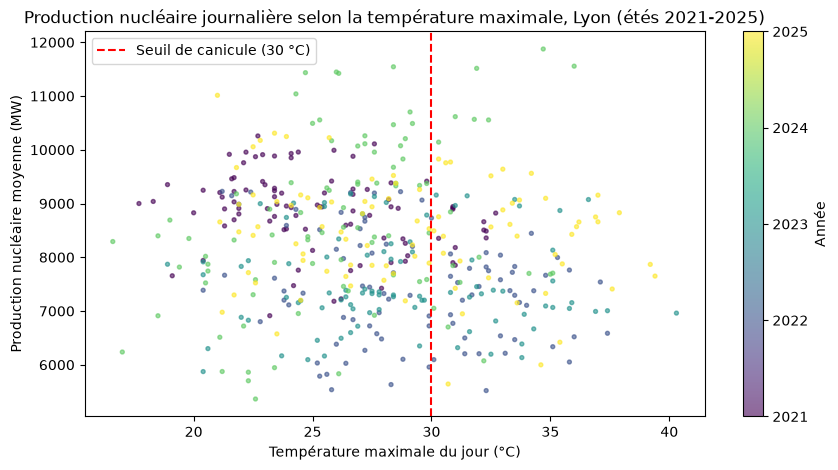

In [25]:
import matplotlib.pyplot as plt

ville = "lyon"
v = ete[ete["ville"] == ville]

fig, ax = plt.subplots(figsize=(10, 5))
nuage = ax.scatter(v["tmax"], v["nucleaire"], s=8, alpha=0.6, c=v["annee"])
fig.colorbar(nuage, label="Année", ticks=[2021, 2022, 2023, 2024, 2025])
ax.axvline(30, color="red", linestyle="--", label="Seuil de canicule (30 °C)")
ax.set_title("Production nucléaire journalière selon la température maximale, " + ville.capitalize() + " (étés 2021-2025)")
ax.set_xlabel("Température maximale du jour (°C)")
ax.set_ylabel("Production nucléaire moyenne (MW)")
ax.legend()
plt.show()


In [26]:
def ecart_canicule(df):
    """Écart (en %) de production nucléaire moyenne entre jours de canicule et autres jours d'été, par ville."""
    moyennes = df.groupby(["ville", "canicule"])["nucleaire"].mean().unstack()
    return ((moyennes[True] / moyennes[False] - 1) * 100).round(1)

comparaison = pd.DataFrame({
    "jours_canicule": ete.groupby("ville")["canicule"].sum(),
    "ecart_toutes_annees_%": ecart_canicule(ete),
    "ecart_sans_2022_%": ecart_canicule(ete[ete["annee"] != 2022]),
})
display(comparaison)


,jours_canicule,ecart_toutes_annees_%,ecart_sans_2022_%
ville,,,
bordeaux,110,-9.3,1.7
lille,21,-8.8,-5.5
lyon,137,-4.7,-3.1
orleans,52,1.2,0.9
rouen,25,-11.3,10.0
strasbourg,70,-15.3,-3.7
toulouse,164,-12.1,-15.1


Conclusions